In [1]:
!pip install -q pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 99.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 94.5 MB/s eta 0:00:00


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import pennylane as qml
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             roc_curve, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PennyLane:", qml.__version__)

Device: cuda | PennyLane: 0.45.1


In [2]:
N_QUBITS = 4          # qubits
N_REPS   = 4          # BasicEntanglerLayers repetitions

PRETRAINED      = False    # True: load backbone weights from your trained binary DNN checkpoint
FREEZE_BACKBONE = False    # True: train only the quantum head (transfer learning, as in the demo)
DNN_CKPT_PATH   = ""

LR_HEAD     = 1e-2    # pre_net + quantum weights + post_net
LR_BACKBONE = 1e-4    # only used if FREEZE_BACKBONE = False
EPOCHS, PATIENCE = 100, 15

In [3]:
df = pd.read_csv("/content/hiv1_protease_padel_full.csv")

fp_cols = [c for c in df.columns if c.startswith("PubchemFP") or
           (c.startswith("FP") and c[2:].isdigit())]

X = df[fp_cols].values.astype(np.float32)
y = df["binary_label"].values.astype(np.float32)      # 1 = active, 0 = inactive
print("Samples:", X.shape[0], "| features:", X.shape[1], "| active fraction:", y.mean().round(3))

X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va   = train_test_split(X_tmp, y_tmp, test_size=0.1765,
                                            stratify=y_tmp, random_state=SEED)

vt = VarianceThreshold(0.01).fit(X_tr)
X_tr, X_va, X_te = vt.transform(X_tr), vt.transform(X_va), vt.transform(X_te)
kept_cols = [str(c) for c in np.array(fp_cols)[vt.get_support()]]
print("Features after variance filter:", X_tr.shape[1])
print("Train/Val/Test:", len(y_tr), len(y_va), len(y_te))

def make_loader(Xa, ya, shuffle, bs=64):
    ds = TensorDataset(torch.tensor(Xa, dtype=torch.float32),
                       torch.tensor(ya, dtype=torch.float32))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle)

train_loader      = make_loader(X_tr, y_tr, True)
train_eval_loader = make_loader(X_tr, y_tr, False)    # unshuffled copy for evaluation
val_loader        = make_loader(X_va, y_va, False)
test_loader       = make_loader(X_te, y_te, False)

Samples: 2577 | features: 881 | active fraction: 0.917
Features after variance filter: 388
Train/Val/Test: 1803 387 387


In [4]:
dev = qml.device("lightning.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # inputs : (batch, N_QUBITS) angles; weights : (N_REPS, N_QUBITS) trainable
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="X")
    qml.BasicEntanglerLayers(weights, wires=range(N_QUBITS))      # RX rotations + ring of CNOTs
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": (N_REPS, N_QUBITS)}

# Quick look at the circuit
print(qml.draw(quantum_circuit)(torch.zeros(N_QUBITS), torch.zeros(N_REPS, N_QUBITS)))

0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
tensor([0., 0., 0., 0.])
M1 = 
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


In [5]:
class HybridDNN(nn.Module):
    def __init__(self, in_dim, n_qubits=N_QUBITS, freeze_backbone=False):
        super().__init__()
        self.freeze_backbone = freeze_backbone

        # ================= Classical backbone (same as the DNN) =================
        # ---- Block 1: in_dim -> 512 ----
        self.fc1   = nn.Linear(in_dim, 512)
        self.bn1   = nn.BatchNorm1d(512)
        self.act1  = nn.ReLU()
        self.drop1 = nn.Dropout(0.3)

        # ---- Block 2: 512 -> 256 ----
        self.fc2   = nn.Linear(512, 256)
        self.bn2   = nn.BatchNorm1d(256)
        self.act2  = nn.ReLU()
        self.drop2 = nn.Dropout(0.3)

        # ---- Block 3: 256 -> 64 ----
        self.fc3   = nn.Linear(256, 64)
        self.bn3   = nn.BatchNorm1d(64)
        self.act3  = nn.ReLU()
        self.drop3 = nn.Dropout(0.3)

        # ================= Quantum head (replaces the DNN's final Linear(64, 1)) =================
        self.pre_net  = nn.Linear(64, n_qubits)                         # 64 -> 4 features for the circuit
        self.qlayer   = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_net = nn.Linear(n_qubits, 1)                          # 4 expectation values -> 1 logit

        if freeze_backbone:
            for m in self.backbone_modules():
                for p in m.parameters():
                    p.requires_grad = False

    def backbone_modules(self):
        return [self.fc1, self.bn1, self.fc2, self.bn2, self.fc3, self.bn3]

    def head_modules(self):
        return [self.pre_net, self.qlayer, self.post_net]

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:                 # frozen backbone: no dropout, BN stats stay fixed
            for m in [self.drop1, self.drop2, self.drop3] + self.backbone_modules():
                m.eval()
        return self

    def forward(self, x):
        # Classical backbone
        x = self.drop1(self.act1(self.bn1(self.fc1(x))))
        x = self.drop2(self.act2(self.bn2(self.fc2(x))))
        x = self.drop3(self.act3(self.bn3(self.fc3(x))))

        # Quantum head
        q_in  = torch.tanh(self.pre_net(x)) * (np.pi / 2.0)    # angles in [-pi/2, pi/2]
        q_out = self.qlayer(q_in).float()                      # (batch, N_QUBITS), values in [-1, 1]
        return self.post_net(q_out).squeeze(1)                 # raw logit

In [6]:
model_q = HybridDNN(X_tr.shape[1], freeze_backbone=FREEZE_BACKBONE)

if PRETRAINED:
    dnn_ckpt = torch.load(DNN_CKPT_PATH, map_location="cpu", weights_only=False)
    assert dnn_ckpt["in_dim"] == X_tr.shape[1], "Feature count differs from the DNN checkpoint"
    assert [str(c) for c in dnn_ckpt["kept_cols"]] == kept_cols, "Feature columns differ from the DNN checkpoint"
    missing, unexpected = model_q.load_state_dict(dnn_ckpt["state_dict"], strict=False)
    print("Not loaded (new quantum head, expected):", [k.split('.')[0] for k in missing][:6], "...")
    print("Ignored from DNN (old output layer, expected):", unexpected)

model_q = model_q.to(device)

n_total     = sum(p.numel() for p in model_q.parameters())
n_trainable = sum(p.numel() for p in model_q.parameters() if p.requires_grad)
n_quantum   = sum(p.numel() for p in model_q.qlayer.parameters())
print(f"Parameters: total {n_total:,} | trainable {n_trainable:,} | quantum circuit weights {n_quantum}")

Parameters: total 348,889 | trainable 348,889 | quantum circuit weights 16


In [7]:
pos_weight = torch.tensor((y_tr == 0).sum() / (y_tr == 1).sum(), dtype=torch.float32).to(device)
print("pos_weight:", pos_weight.item())
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

head_params = [p for m in model_q.head_modules() for p in m.parameters()]
param_groups = [{"params": head_params, "lr": LR_HEAD}]
if not FREEZE_BACKBONE:
    param_groups.append({"params": [p for m in model_q.backbone_modules() for p in m.parameters()],
                         "lr": LR_BACKBONE})

optimizer = torch.optim.AdamW(param_groups, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)

@torch.no_grad()
def predict_proba_q(model, loader):
    model.eval()
    out = [torch.sigmoid(model(xb.to(device))).cpu() for xb, _ in loader]
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_loss_q(model, loader):
    model.eval(); total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        total += criterion(model(xb), yb).item() * len(yb); n += len(yb)
    return total / n

pos_weight: 0.09008464217185974


In [8]:
BEST_WEIGHTS_PATH = "hiv1_hybrid_best_weights.pt"
CHECKPOINT_PATH   = "hiv1_hybrid_best_checkpoint.pt"

best_auc, best_state, best_epoch, wait = -1.0, None, 0, 0
history_q = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_auc": []}

for epoch in range(1, EPOCHS + 1):
    # ---- train ----
    model_q.train(); running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model_q(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb); n += len(yb)

    # ---- evaluate ----
    train_prob = predict_proba_q(model_q, train_eval_loader)
    val_prob   = predict_proba_q(model_q, val_loader)
    train_acc  = accuracy_score(y_tr, train_prob >= 0.5)
    val_acc    = accuracy_score(y_va, val_prob >= 0.5)
    val_auc    = roc_auc_score(y_va, val_prob)

    history_q["train_loss"].append(running / n)
    history_q["val_loss"].append(eval_loss_q(model_q, val_loader))
    history_q["train_acc"].append(train_acc)
    history_q["val_acc"].append(val_acc)
    history_q["val_auc"].append(val_auc)
    scheduler.step(val_auc)

    # ---- early stopping / keep and save best model (by validation AUC) ----
    if val_auc > best_auc:
        best_auc, best_epoch, wait = val_auc, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model_q.state_dict().items()}
        torch.save(best_state, BEST_WEIGHTS_PATH)
    else:
        wait += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | loss {history_q['train_loss'][-1]:.4f}/{history_q['val_loss'][-1]:.4f} "
              f"| acc {train_acc:.4f}/{val_acc:.4f} | val AUC {val_auc:.4f}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best val AUC {best_auc:.4f} at epoch {best_epoch})")
        break

model_q.load_state_dict(best_state)

torch.save({
    "state_dict": best_state,
    "in_dim": int(X_tr.shape[1]),
    "kept_cols": kept_cols,
    "n_qubits": N_QUBITS,
    "n_reps": N_REPS,
    "freeze_backbone": bool(FREEZE_BACKBONE),
    "best_val_auc": float(best_auc),
    "best_epoch": int(best_epoch),
}, CHECKPOINT_PATH)

print(f"\nBest model: epoch {best_epoch}, val AUC {best_auc:.4f}")
print(f"Saved: {BEST_WEIGHTS_PATH} and {CHECKPOINT_PATH}")

epoch   1 | loss 0.1143/0.1114 | acc 0.8458/0.8114 | val AUC 0.7132
epoch   5 | loss 0.0742/0.0751 | acc 0.8902/0.8165 | val AUC 0.8732
epoch  10 | loss 0.0484/0.0751 | acc 0.9113/0.8450 | val AUC 0.8842
epoch  15 | loss 0.0451/0.0628 | acc 0.8913/0.8295 | val AUC 0.9023
epoch  20 | loss 0.0419/0.0642 | acc 0.9057/0.8501 | val AUC 0.9076
epoch  25 | loss 0.0440/0.0669 | acc 0.9090/0.8372 | val AUC 0.9045
epoch  30 | loss 0.0418/0.0701 | acc 0.9118/0.8527 | val AUC 0.8974
epoch  35 | loss 0.0377/0.0739 | acc 0.9201/0.8630 | val AUC 0.8952
Early stopping at epoch 38 (best val AUC 0.9118 at epoch 23)

Best model: epoch 23, val AUC 0.9118
Saved: hiv1_hybrid_best_weights.pt and hiv1_hybrid_best_checkpoint.pt


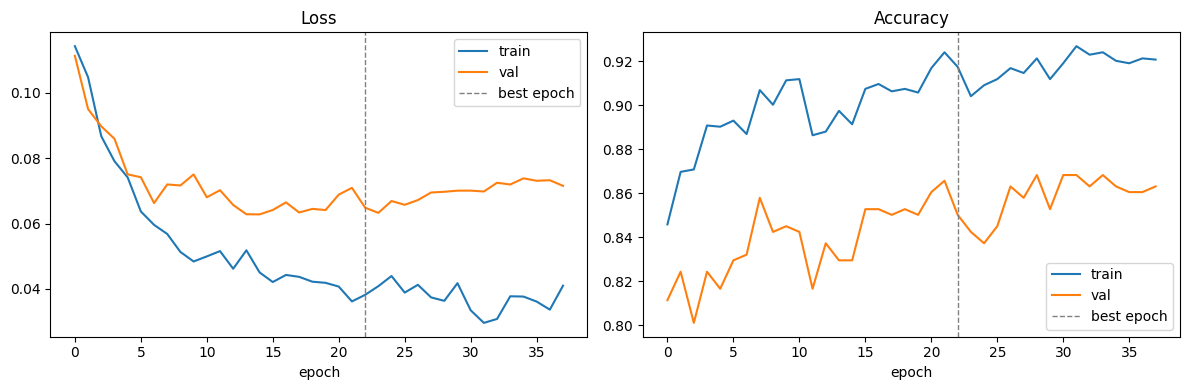

Best epoch: 23
Train acc: 0.9174 | Val acc: 0.8501


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history_q["train_loss"], label="train")
ax[0].plot(history_q["val_loss"], label="val")
ax[0].axvline(best_epoch - 1, color="gray", ls="--", lw=1, label="best epoch")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history_q["train_acc"], label="train")
ax[1].plot(history_q["val_acc"], label="val")
ax[1].axvline(best_epoch - 1, color="gray", ls="--", lw=1, label="best epoch")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

i = best_epoch - 1
print(f"Best epoch: {best_epoch}")
print(f"Train acc: {history_q['train_acc'][i]:.4f} | Val acc: {history_q['val_acc'][i]:.4f}")

pd.DataFrame(history_q).round(4).to_csv("hybrid_training_history.csv", index_label="epoch")

In [10]:
val_prob_q  = predict_proba_q(model_q, val_loader)
test_prob_q = predict_proba_q(model_q, test_loader)

thresholds = np.linspace(0.05, 0.95, 91)
best_t_q = thresholds[np.argmax([balanced_accuracy_score(y_va, val_prob_q >= t) for t in thresholds])]
print("Chosen threshold:", round(float(best_t_q), 2))

def report_q(thr):
    pred = (test_prob_q >= thr).astype(int)
    return {"threshold": round(float(thr), 2),
            "accuracy": accuracy_score(y_te, pred),
            "balanced_acc": balanced_accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC_AUC": roc_auc_score(y_te, test_prob_q),
            "PR_AUC": average_precision_score(y_te, test_prob_q)}

res_q = pd.DataFrame({"Hybrid QML (thr=0.5)": report_q(0.5),
                      "Hybrid QML (tuned thr)": report_q(best_t_q)}).T.round(3)
display(res_q)
res_q.to_csv("hybrid_test_results.csv")

# Side by side with the classical DNN, if its results table is still in memory
if "res" in globals():
    display(pd.concat([res, res_q]))

Chosen threshold: 0.47


,threshold,accuracy,balanced_acc,precision,recall,F1,ROC_AUC,PR_AUC
Hybrid QML (thr=0.5),0.50,0.884,0.837,0.978,0.893,0.934,0.841,0.974
Hybrid QML (tuned thr),0.47,0.886,0.839,0.978,0.896,0.935,0.841,0.974


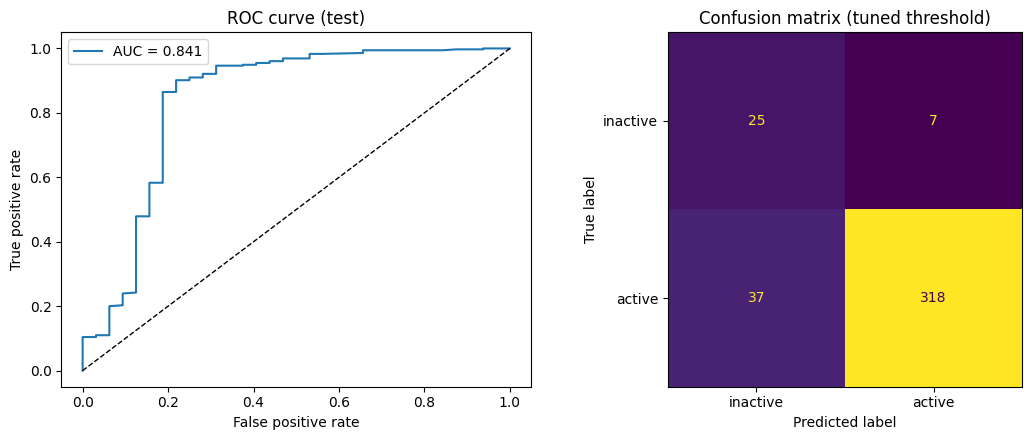

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

fpr, tpr, _ = roc_curve(y_te, test_prob_q)
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, test_prob_q):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (test)"); ax[0].legend()

cm = confusion_matrix(y_te, (test_prob_q >= best_t_q).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["inactive", "active"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Confusion matrix (tuned threshold)")

plt.tight_layout(); plt.show()

In [12]:
idx = np.arange(len(y))
idx_tmp, idx_te = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)
assert np.array_equal(y[idx_te], y_te), "Index split does not match the split cell"

pred_tuned_q = (test_prob_q >= best_t_q).astype(int)
pred_df_q = pd.DataFrame({
    "molecule_chembl_id": df.iloc[idx_te]["molecule_chembl_id"].values,
    "canonical_smiles":   df.iloc[idx_te]["canonical_smiles"].values,
    "pIC50":              df.iloc[idx_te]["pIC50"].values,
    "true_label":         y_te.astype(int),
    "prob_active":        test_prob_q.round(4),
    "pred_label":         pred_tuned_q,
})
pred_df_q["correct"] = pred_df_q.true_label == pred_df_q.pred_label
pred_df_q.to_csv("hybrid_test_predictions.csv", index=False)
display(pred_df_q.groupby("true_label").correct.mean().rename("accuracy per class"))

# Re-save checkpoint with the threshold (plain Python types only)
torch.save({
    "state_dict": best_state,
    "in_dim": int(X_tr.shape[1]),
    "kept_cols": kept_cols,
    "n_qubits": N_QUBITS,
    "n_reps": N_REPS,
    "freeze_backbone": bool(FREEZE_BACKBONE),
    "best_val_auc": float(best_auc),
    "best_epoch": int(best_epoch),
    "threshold": float(best_t_q),
}, CHECKPOINT_PATH)

# from google.colab import files
# files.download(CHECKPOINT_PATH)
# files.download("hybrid_test_results.csv")
# files.download("hybrid_test_predictions.csv")

,accuracy per class
true_label,
0,0.781250
1,0.895775


In [13]:
ckpt_q = torch.load("/content/hiv1_hybrid_best_checkpoint.pt", map_location=device)
model_r = HybridDNN(ckpt_q["in_dim"], ckpt_q["n_qubits"], ckpt_q["freeze_backbone"]).to(device)
model_r.load_state_dict(ckpt_q["state_dict"])
model_r.eval()
threshold_q = ckpt_q["threshold"]
print("Loaded | best epoch:", ckpt_q["best_epoch"], "| val AUC:", round(ckpt_q["best_val_auc"], 4),
      "| threshold:", round(threshold_q, 2))

prob_r = predict_proba_q(model_r, test_loader)
pred_r = (prob_r >= threshold_q).astype(int)

print(f"\nTest accuracy:          {accuracy_score(y_te, pred_r):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_te, pred_r):.4f}")
print(f"Test ROC-AUC:           {roc_auc_score(y_te, prob_r):.4f}")

# Sanity check: should be ~0 if the reload matches the trained model
print("Max difference vs earlier test_prob_q:", np.abs(prob_r - test_prob_q).max())

Loaded | best epoch: 23 | val AUC: 0.9118 | threshold: 0.47

Test accuracy:          0.8863
Test balanced accuracy: 0.8385
Test ROC-AUC:           0.8408
Max difference vs earlier test_prob_q: 0.0
